# clone — GitHub 기반 24시간 조기경보 실험

원본: [ki-seoultech](https://github.com/ki-seoultech/PHM2018-Ion-Mill-Etch-3Stage-Predictive-Maintenance). **RUL 원본의 정확한 재현이 아니라, 구조·특징 추출을 옮긴 24시간 이진 분류 실험**입니다.

학습은 이미 실행해 가중치를 `artifacts/`에 저장했습니다. 이 노트북은 결과를 읽어 표·그림을 다시 만듭니다. 전처리와 차이는 [README](README.md), 전체 결과는 [REPORT](results/REPORT.md)를 보세요.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from IPython.display import display
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'models/clone/results/summary.csv').exists())
clone = root / 'models/clone'
summary = pd.read_csv(clone / 'results/summary.csv')
manifest = json.loads((clone / 'results/manifest.json').read_text(encoding='utf-8'))
print('원본 커밋:', manifest['source_commit'])
print('실행 GPU:', manifest['device'])
print('입력 구간:', f"{manifest['rows']:,}", '| 장비:', len(sum(manifest['unseen_tool_folds'], [])))

원본 커밋: 6ba6b026340cd21a95f8846344c1996a02bcc97d
실행 GPU: NVIDIA GeForce RTX 2060
입력 구간: 526,268 | 장비: 20


## 1. 같은 장비 / 처음 보는 장비 성능

보정 구간에서 항상 경보 대비 정밀도 4배를 목표로 정한 '즉시 점검' 기준입니다. 평가 구간에서 반드시 4배가 된다는 뜻은 아닙니다. Precision/Recall/F1은 장비-일 단위입니다.

In [2]:
columns = ['validation', 'model', 'precision', 'recall', 'f1', 'accuracy', 'auc', 'pr_auc', 'days', 'positive_days', 'alarm_days']
display(summary.loc[summary.lift_target.eq(4), columns].round(4))

,validation,model,precision,recall,f1,accuracy,auc,pr_auc,days,positive_days,alarm_days
1,same_tools,baseline_lr13,0.2120,0.8030,0.3354,0.7973,0.8959,0.6657,2072,132,500
3,same_tools,clone_hgbm,0.1617,0.6212,0.2567,0.7708,0.7105,0.2534,2072,132,507
5,same_tools,clone_xgb_smote,0.1619,0.5530,0.2504,0.7891,0.7057,0.2463,2072,132,451
7,same_tools,clone_gru,0.0000,0.0000,0.0000,0.9363,0.5464,0.1120,2072,132,0
9,same_tools,clone_hgbm_gru,0.1489,0.6136,0.2396,0.7519,0.6591,0.2243,2072,132,544
11,unseen_tools,baseline_lr13,0.1971,0.8333,0.3188,0.7732,0.8691,0.6618,2072,132,558
13,unseen_tools,clone_hgbm,0.0710,0.0985,0.0825,0.8605,0.4286,0.0584,2072,132,183
15,unseen_tools,clone_xgb_smote,0.0709,0.4773,0.1234,0.5681,0.4288,0.0525,2072,132,889
17,unseen_tools,clone_gru,0.0465,0.2121,0.0763,0.6728,0.4619,0.0542,2072,132,602
19,unseen_tools,clone_hgbm_gru,0.0421,0.1364,0.0643,0.7471,0.4416,0.0552,2072,132,428


## 2. 주의 / 즉시 점검 기준 비교

In [3]:
display(summary[['validation', 'model', 'lift_target', 'precision', 'recall', 'f1', 'fp', 'fn', 'tp', 'tn']].round(4))

,validation,model,lift_target,precision,recall,f1,fp,fn,tp,tn
0,same_tools,baseline_lr13,2,0.1320,0.9318,0.2312,809,9,123,1131
1,same_tools,baseline_lr13,4,0.2120,0.8030,0.3354,394,26,106,1546
2,same_tools,clone_hgbm,2,0.0908,0.7424,0.1618,981,34,98,959
3,same_tools,clone_hgbm,4,0.1617,0.6212,0.2567,425,50,82,1515
4,same_tools,clone_xgb_smote,2,0.0940,0.7424,0.1670,944,34,98,996
5,same_tools,clone_xgb_smote,4,0.1619,0.5530,0.2504,378,59,73,1562
6,same_tools,clone_gru,2,0.0711,0.2727,0.1129,470,96,36,1470
7,same_tools,clone_gru,4,0.0000,0.0000,0.0000,0,132,0,1940
8,same_tools,clone_hgbm_gru,2,0.0839,0.7045,0.1500,1015,39,93,925
9,same_tools,clone_hgbm_gru,4,0.1489,0.6136,0.2396,463,51,81,1477


## 3. Precision–recall 곡선

같은 평가일의 곡선을 비교합니다. PR-AUC는 scikit-learn average precision 정의입니다. 처음 보는 장비의 합산 곡선은 서로 다른 4개 모델 점수를 모은 참고치입니다.

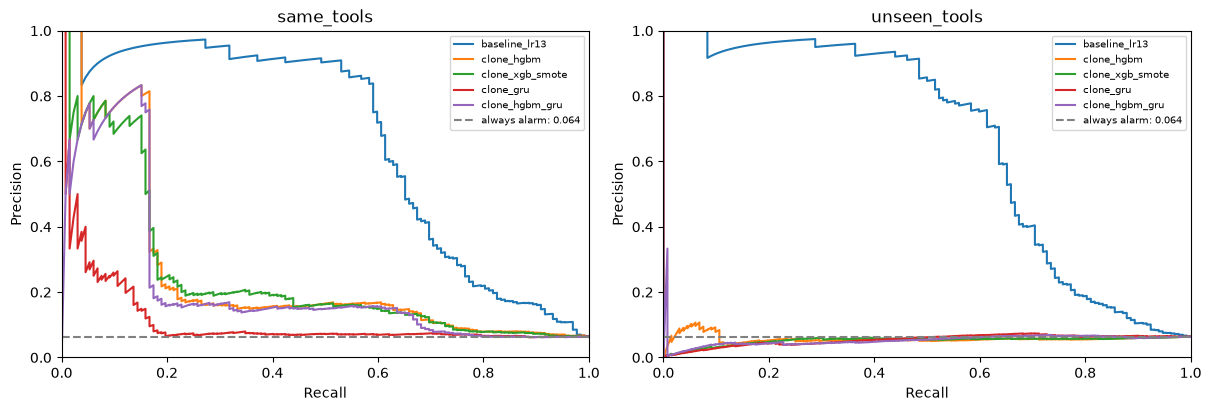

In [4]:
predictions = pd.read_csv(clone / 'results/test_day_predictions.csv')
figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for axis, name in zip(axes, ['same_tools', 'unseen_tools']):
    selected = predictions[predictions.fold.eq('same_tools')] if name == 'same_tools' else predictions[predictions.fold.str.startswith('unseen_')]
    for model, group in selected.groupby('model', sort=False):
        precision, recall, thresholds = precision_recall_curve(group.label, group.score)
        axis.plot(recall, precision, label=model)
    base = selected[selected.model.eq('baseline_lr13')].label.mean()
    axis.axhline(base, linestyle='--', color='grey', label=f'always alarm: {base:.3f}')
    axis.set(title=name, xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1))
    axis.legend(fontsize=7)
figure.savefig(clone / 'results/precision_recall.png', dpi=150)
plt.show()

## 4. GRU 학습 이력

train loss가 줄어도 validation loss가 증가하면 과적합입니다. 선택은 학습 구간 내부의 검증 손실로만 했습니다.

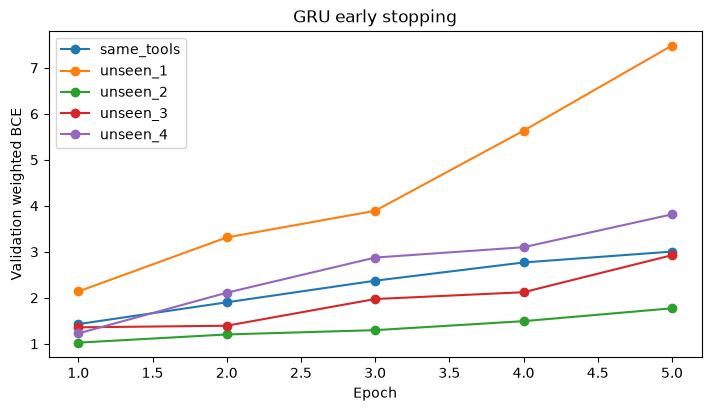

In [5]:
figure, axis = plt.subplots(figsize=(7, 4), constrained_layout=True)
for folder in sorted((clone / 'artifacts').iterdir()):
    history = pd.read_csv(folder / 'gru_history.csv')
    axis.plot(history.epoch, history.validation_loss, marker='o', label=folder.name)
axis.set(xlabel='Epoch', ylabel='Validation weighted BCE', title='GRU early stopping')
axis.legend()
figure.savefig(clone / 'results/gru_validation.png', dpi=150)
plt.show()

## 5. 결론과 한계

같은 장비의 미래 평가에서 재학습 LR의 F1은 **33.5%**, clone 중 최고 F1은
**25.7% (clone HGBM)** 이다. 이번 적용에서는 LR이 우세하다.
처음 보는 장비 성능은 아래 합산 결과와 `fold_metrics.csv`를 함께 본다.

평가 **2,072 장비-일**, 양성 **132일 (6.37%)**.
임계값은 보정 구간에서 정밀도 4배를 목표로 정했고, 평가 구간에 그대로 적용했다.
모든 모델에 같은 일별 정답·평가 행을 사용했다.



이전 2,082일 실험과 달라진 라벨·분할 규칙 때문에, 이번에 다시 학습한 LR을 기준으로 비교합니다. 고장 이력 입력을 사용하므로 신규 설치 직후처럼 이력이 전혀 없는 장비 성능은 아닙니다. 고장 사건별 선행시간은 이 일별 점수와 별도로 검증해야 합니다.

## 6. 전체 학습 재실행

터미널에서 실행합니다. 이 명령은 현재 PC의 Python 경로입니다. 다른 환경에서는 경로를 바꾸세요.

```powershell
& 'C:/Users/rhkdd/anaconda3/python.exe' -X utf8 -u models/clone/run_clone.py --folds all --epochs 20
```